# Масштабирование данных

## Для чего нужно масштабирование

Обучим модель для регрессии из `sklearn` на датасете про недвижимость.

In [ ]:
from sklearn.datasets import fetch_california_housing
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.tree import plot_tree

from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler

In [ ]:
data = fetch_california_housing()
X = pd.DataFrame(data['data'], columns=data['feature_names'])
y = data['target']

X.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0000,6.9841,1.0238,322.0000,2.5556,37.8800,-122.2300
1,8.3014,21.0000,6.2381,0.9719,2401.0000,2.1098,37.8600,-122.2200
2,7.2574,52.0000,8.2881,1.0734,496.0000,2.8023,37.8500,-122.2400
3,5.6431,52.0000,5.8174,1.0731,558.0000,2.5479,37.8500,-122.2500
4,3.8462,52.0000,6.2819,1.0811,565.0000,2.1815,37.8500,-122.2500


In [ ]:
# Разобьем выборку на обучение и тест с помощью `train_test_split`.
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=10, test_size=0.2)
X_train.shape, X_test.shape

((16512, 8), (4128, 8))

In [ ]:
# инициализируем модель `KNeighborsRegressor` для задачи регрессии из `sklearn`.
knn = KNeighborsRegressor()

In [ ]:
# обучаем на обучающей выборке.
knn.fit(X_train, y_train)

KNeighborsRegressor()

In [ ]:
# Делаем предсказание и считаем метрики качества
pred_train = knn.predict(X_train)
pred_test = knn.predict(X_test)

print(f'Train R2 {r2_score(y_train, pred_train):.2f}')
print(f'Test R2 {r2_score(y_test, pred_test):.2f}')

Train R2 0.45
Test R2 0.18


In [ ]:
# Пробуем другую модель
lr = LinearRegression()
lr.fit(X_train, y_train)

LinearRegression()

In [ ]:
pred_train = lr.predict(X_train)
pred_test = lr.predict(X_test)

print(f'Train R2 {r2_score(y_train, pred_train):.2f}')
print(f'Test R2 {r2_score(y_test, pred_test):.2f}')

Train R2 0.61
Test R2 0.60


Метрики выше, но не настолько хорошие, чтобы пускать модель к реальным данным.
Данная модель линейная, простая, поэтому и высокого качества можно не ожидать. Возьмем ещё одну модель. Делаем предположение, что может быть задача очень сложная, и наши предыдущие модели машинного обучения не справляются с ней.

In [ ]:
# Обучим дерево решений
tree_1 = DecisionTreeRegressor(random_state=1, max_depth=9)
tree_1.fit(X_train, y_train)

DecisionTreeRegressor(max_depth=9, random_state=1)

In [ ]:
pred_train = tree_1.predict(X_train)
pred_test = tree_1.predict(X_test)


print(f'Train R2 {r2_score(y_train, pred_train):.2f}')
print(f'Test R2 {r2_score(y_test, pred_test):.2f}')

Train R2 0.79
Test R2 0.72


В результате, видно, т.к. модель дерева решений обучилась на этих данных, то проблема не в данных, а в моделях. KNN, линейные модели и другие модели очень чувстительны ко входным данным. Посмотрим на эти данные.



In [ ]:
X.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
count,20640.0000,20640.0000,20640.0000,20640.0000,20640.0000,20640.0000,20640.0000,20640.0000
mean,3.8707,28.6395,5.4290,1.0967,1425.4767,3.0707,35.6319,-119.5697
std,1.8998,12.5856,2.4742,0.4739,1132.4621,10.3860,2.1360,2.0035
min,0.4999,1.0000,0.8462,0.3333,3.0000,0.6923,32.5400,-124.3500
25%,2.5634,18.0000,4.4407,1.0061,787.0000,2.4297,33.9300,-121.8000
50%,3.5348,29.0000,5.2291,1.0488,1166.0000,2.8181,34.2600,-118.4900
75%,4.7432,37.0000,6.0524,1.0995,1725.0000,3.2823,37.7100,-118.0100
max,15.0001,52.0000,141.9091,34.0667,35682.0000,1243.3333,41.9500,-114.3100


присутствуют признаки с маленькими значениями (`MedInc`, `AveBedrms`), и присутствуют признаки со значениями побольше (`Latitude`, `HouseAge`), а есть  с очень большими значениями (`Population` и `AveOccup`). Значения в признаках **отличаются на порядки** и это огромная **проблема** для чувствительных моделей.


Имея такие данные, модель может ошибочно считать, что раз признак большой (`Population`), то он полезный, но какие-нибудь маленькие признаки (`MedInc`) могут оказаться в разы полезней больших. А вот такие большие будут перетягивать на себя всё внимание модели.

<img src='https://drive.google.com/uc?id=19e_j7M6XJ2pvypKfXqwn3V6eXwYIUO8m'>

Следовательно необходимо признаки уравнять (масштабировать) чтобы модель изначально считала, что всё признаки одинаково полезные и никакому признаку не давала возможность забирать на себя основное внимание.

## Масштабирование данных

### Нормализация

Для того, чтобы сделать нормализацию данных нужно посчитать в каждом признаке его минимум (min) и максимум (max), а затем сделать следующее вычисление:

$$x = \frac{x - min}{max - min}$$

После такого преобразования $min = 0, max = 1$.

In [ ]:
# Обучим sklearn версию
mms = MinMaxScaler()
mms.fit(X_train)

MinMaxScaler()

In [ ]:
# найдем мнинимальные значения признаков
X_train.min()

,0
MedInc,0.499900
HouseAge,1.000000
AveRooms,0.846154
AveBedrms,0.333333
Population,3.000000
AveOccup,0.692308
Latitude,32.540000
Longitude,-124.350000


In [ ]:
# найдем максимальные значения признаков
X_train.max()

,0
MedInc,15.000100
HouseAge,52.000000
AveRooms,141.909091
AveBedrms,34.066667
Population,35682.000000
AveOccup,599.714286
Latitude,41.950000
Longitude,-114.310000


In [ ]:
#  номализуем обучающую выборку и обернем ее в DataFrame
X_train_norm = pd.DataFrame(mms.transform(X_train), columns=X_train.columns)
X_train_norm.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
count,16512.0000,16512.0000,16512.0000,16512.0000,16512.0000,16512.0000,16512.0000,16512.0000
mean,0.2320,0.5414,0.0325,0.0227,0.0399,0.0039,0.3294,0.4754
std,0.1304,0.2476,0.0184,0.0149,0.0318,0.0107,0.2273,0.1998
min,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
25%,0.1420,0.3333,0.0254,0.0199,0.0219,0.0029,0.1477,0.2540
50%,0.2091,0.5490,0.0310,0.0212,0.0326,0.0035,0.1828,0.5827
75%,0.2924,0.7059,0.0369,0.0227,0.0484,0.0043,0.5505,0.6315
max,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000


Все минимальные значения везде равны 0, а максимальные  - 1.

Нормализуем тестовую выборку. При этом пользуемся `min` и `max` значениями с **обучающей** выборки, на тесте **ничего никогда не считается**.

In [ ]:
X_test_norm = pd.DataFrame(mms.transform(X_test), columns=X_train.columns)
X_test_norm.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
count,4128.000000,4128.000000,4128.000000,4128.000000,4128.000000,4128.000000,4128.000000,4128.000000
mean,0.234496,0.544198,0.032414,0.022440,0.039816,0.004262,0.325244,0.478847
std,0.133330,0.243659,0.013532,0.010172,0.031321,0.032298,0.225655,0.198421
min,0.000000,0.000000,0.002015,0.003294,0.000056,0.000465,0.002125,0.004980
25%,0.143938,0.333333,0.025715,0.019910,0.022142,0.002904,0.148778,0.258715
50%,0.210390,0.549020,0.031240,0.021195,0.032680,0.003552,0.180659,0.584661
75%,0.294279,0.705882,0.036861,0.022743,0.047619,0.004325,0.548353,0.631474
max,1.000000,1.000000,0.436515,0.408432,0.451778,2.074450,0.988310,0.982072


Видно, что чистый 0 в `min` и 1 в `max`мы не получили, это как раз-таки из-за того, что используем `min` и `max` из обучения.

Так проиходит, потому что на тесте нет цели получить сто процентный 0 и 1, цель - **перевести данные в такую же шкалу**, что получили на трейне.

Ведь действительно у нас на обучении самый густонаселенный дом вмещает 35к людей, а вот на тесте всего лишь 16к, меньше в два раза, чем на обучении, поэтому и максимальное значение в `Population` с теста оказывается на половине шкалы с обучения.

In [ ]:
X_train['Population'].max(), X_test['Population'].max()

(35682.0, 16122.0)

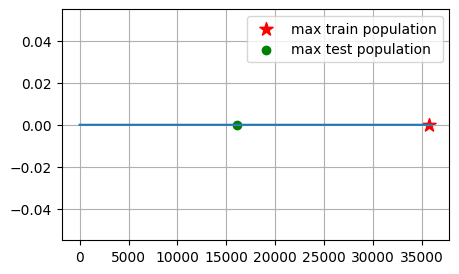

In [ ]:
x = np.arange(0, 36000)
y = 0 * x
plt.figure(figsize = (5,3))
plt.plot(x, y)
plt.scatter([X_train['Population'].max()], [0], label='max train population', marker='*', c='r', s=100)
plt.scatter([X_test['Population'].max()], [0], label='max test population', marker='o', c='g')
plt.grid()
plt.legend();

Тоже самое будет и в масштабированном виде.

In [ ]:
X_train_norm['Population'].max(), X_test_norm['Population'].max()

(1.0, 0.4517783570167325)

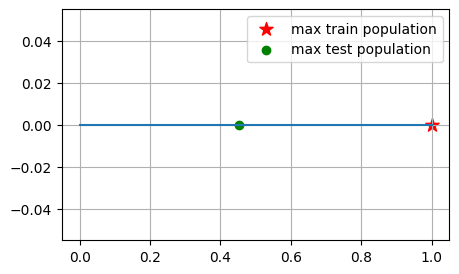

In [ ]:
plt.figure(figsize = (5,3))
x = np.linspace(0, 1, 5)
y = 0 * x
plt.plot(x, y)
plt.scatter([X_train_norm['Population'].max()], [0], label='max train population', marker='*', c='r', s=100)
plt.scatter([X_test_norm['Population'].max()], [0], label='max test population', marker='o', c='g')
plt.grid()
plt.legend();

Так что это абсолютная норма, что на тесте данные не принимают в максимальном 1, а в минимальном 0.

#### Обучение модели на масштабированных данных

In [ ]:
# обучение модели knn на нормализованных данных
knn = KNeighborsRegressor()
knn.fit(X_train_norm, y_train)

KNeighborsRegressor()

In [ ]:
# получение предсказания на нормализованных данных
pred_train = knn.predict(X_train_norm)
pred_test = knn.predict(X_test_norm)


print(f'Train R2 {r2_score(y_train, pred_train):.2f}')
print(f'Test R2 {r2_score(y_test, pred_test):.2f}')

Train R2 0.81
Test R2 0.70


Для справки, что было до
```
Train R2 0.45
Test R2 0.18
```

После нормализации качество заметно выросло. Проблема состояла в том, что в немасштабированных данных, признаки с большими значениями, собой перекрывали все остальные признаки.

In [ ]:
# обучение модели линейной регрессии на нормализованных данных
lr = LinearRegression()
lr.fit(X_train_norm, y_train)

LinearRegression()

In [ ]:
# получение предсказаний и расчет метрик
pred_train = lr.predict(X_train_norm)
pred_test = lr.predict(X_test_norm)


print(f'Train R2 {r2_score(y_train, pred_train):.2f}')
print(f'Test R2 {r2_score(y_test, pred_test):.2f}')

Train R2 0.61
Test R2 0.60


Для справки, что было до



```
Train R2 0.61
Test R2 0.60
```



Ничего не изменилось, потому что **линейным моделям** больше подходит следующий метод масштабирования данных - **стандартизация** (или мы выжали все соки из линейной регрессии)

### Стандартизация

Для того, чтобы сделать стандартизацию данных нужно посчитать в каждом признаке его среднее значение (`mean`) и стандартное отклонение (`std`), а затем сделать следующее вычисление:

$$x = \frac{x - mean}{std}$$

После такого преобразования $mean = 0, std = 1$.

Обучаем при помощи sklearn

In [ ]:
scaler = StandardScaler()
scaler.fit(X_train)

StandardScaler()

Стандартизатор обучился, посмотрим, какими были средние значения в признаках.

In [ ]:
X_train.mean()

,0
MedInc,3.863304
HouseAge,28.610828
AveRooms,5.431610
AveBedrms,1.098265
Population,1425.947977
AveOccup,3.026987
Latitude,35.639689
Longitude,-119.576537


И посмотрим, какие были стандартные отклонения в признаках.

In [ ]:
X_train.std()

,0
MedInc,1.891345
HouseAge,12.625188
AveRooms,2.596377
AveBedrms,0.501296
Population,1136.202481
AveOccup,6.424072
Latitude,2.139067
Longitude,2.006371


А теперь можем привести к стандартному виду нашу обучающую выборку.

In [ ]:
X_train_std = pd.DataFrame(scaler.transform(X_train), columns=X_train.columns)
X_train_std.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
count,16512.0000,16512.0000,16512.0000,16512.0000,16512.0000,16512.0000,16512.0000,16512.0000
mean,-0.0000,0.0000,0.0000,0.0000,-0.0000,-0.0000,0.0000,0.0000
std,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
min,-1.7784,-2.1870,-1.7662,-1.5260,-1.2524,-0.3634,-1.4491,-2.3792
25%,-0.6895,-0.8405,-0.3840,-0.1835,-0.5641,-0.0931,-0.7993,-1.1082
50%,-0.1749,0.0308,-0.0807,-0.0986,-0.2292,-0.0326,-0.6450,0.5366
75%,0.4634,0.6645,0.2402,0.0019,0.2676,0.0396,0.9726,0.7808
max,5.8885,1.8526,52.5662,65.7683,30.1505,92.8858,2.9501,2.6250


Если и в pandas хочется избавиться от научной записи чисел, то выполняйте следующую строку кода

In [ ]:
pd.set_option('display.float_format', lambda x: '%0.4f' % x)
X_train_std.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
count,16512.0000,16512.0000,16512.0000,16512.0000,16512.0000,16512.0000,16512.0000,16512.0000
mean,-0.0000,0.0000,0.0000,0.0000,-0.0000,-0.0000,0.0000,0.0000
std,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
min,-1.7784,-2.1870,-1.7662,-1.5260,-1.2524,-0.3634,-1.4491,-2.3792
25%,-0.6895,-0.8405,-0.3840,-0.1835,-0.5641,-0.0931,-0.7993,-1.1082
50%,-0.1749,0.0308,-0.0807,-0.0986,-0.2292,-0.0326,-0.6450,0.5366
75%,0.4634,0.6645,0.2402,0.0019,0.2676,0.0396,0.9726,0.7808
max,5.8885,1.8526,52.5662,65.7683,30.1505,92.8858,2.9501,2.6250


И да, теперь среднее во всех признаках равно 0, а стандартное отклонение равно 1. Стандартизируем тестовую выборку. При этом пользуемся `mean` и `std` значениями с обучающей выборке, на тесте ничего никогда не считается.

In [ ]:
X_test_std = pd.DataFrame(scaler.transform(X_test), columns=X_train.columns)
X_test_std.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
count,4128.0000,4128.0000,4128.0000,4128.0000,4128.0000,4128.0000,4128.0000,4128.0000
mean,0.0195,0.0113,-0.0050,-0.0159,-0.0021,0.0340,-0.0183,0.0170
std,1.0222,0.9843,0.7352,0.6845,0.9836,3.0118,0.9927,0.9929
min,-1.7784,-2.1870,-1.6567,-1.3043,-1.2506,-0.3201,-1.4398,-2.3543
25%,-0.6748,-0.8405,-0.3690,-0.1861,-0.5571,-0.0926,-0.7946,-1.0846
50%,-0.1653,0.0308,-0.0688,-0.0997,-0.2262,-0.0322,-0.6544,0.5465
75%,0.4778,0.6645,0.2366,0.0045,0.2430,0.0398,0.9632,0.7808
max,5.8885,1.8526,21.9507,25.9592,12.9348,193.0775,2.8987,2.5353


Аналогично, где-то мы не получили чистый 0 в `mean` и 1 в `std`, это снова из-за того, что используем `mean` и `std` с обучения.

На тесте нет цели получить сто процентный 0 и 1, цель - **перевести данные в такую же шкалу**, что получили на трейне.

#### Обучение модели на масштабированных данных

Снова повторим обучение моделей, но уже на стандартизированных данных.

In [ ]:
knn = KNeighborsRegressor()
knn.fit(X_train_std, y_train)

KNeighborsRegressor()

In [ ]:
pred_train = knn.predict(X_train_std)
pred_test = knn.predict(X_test_std)


print(f'Train R2 {r2_score(y_train, pred_train):.2f}')
print(f'Test R2 {r2_score(y_test, pred_test):.2f}')

Train R2 0.81
Test R2 0.70


Для справки, что было до



```
исходные данные
Train R2 0.45
Test R2 0.18

после нормализации
Train R2 0.81
Test R2 0.70
```



Качество выросло, при этом здесь оно такое же, как и после нормализации данных.

Попробуем другую модель.

In [ ]:
lr = LinearRegression()
lr.fit(X_train_std, y_train)

LinearRegression()

In [ ]:
pred_train = lr.predict(X_train_std)
pred_test = lr.predict(X_test_std)


print(f'Train R2 {r2_score(y_train, pred_train):.2f}')
print(f'Test R2 {r2_score(y_test, pred_test):.2f}')

Train R2 0.61
Test R2 0.60


Для справки, что было до



```
исходные данные
Train R2 0.61
Test R2 0.60

после нормализации
Train R2 0.61
Test R2 0.60
```



Изменений нет, делаем вывод, что в этом случае наши данные не вызывают дискомфорта у линейной модели, при любом способе масштабирования данных результат будет одинаковым.

Однозначно, лишним не будет сделать масштабирование данных для таких моделей.

Для эксперимента обучим дерево решений и сравним его метрики.

In [ ]:
tree_2 = DecisionTreeRegressor(random_state=1, max_depth=9)
tree_2.fit(X_train_norm, y_train)

DecisionTreeRegressor(max_depth=9, random_state=1)

```
метрики до
Train R2 0.79
Test R2 0.72
```

In [ ]:
pred_train = tree_2.predict(X_train_norm)
pred_test = tree_2.predict(X_test_norm)


print(f'Train R2 {r2_score(y_train, pred_train):.2f}')
print(f'Test R2 {r2_score(y_test, pred_test):.2f}')

Train R2 0.79
Test R2 0.72


Видно, что метрики не изменились, т.к. дереву решений не важно, какой масштаб у признака, дерево решений задает вопросы к данным. Если мы применем масштабирование, то вопросы к признакам не изменятся, изменится только пороговое значение, с которым сравнивается вопрос.

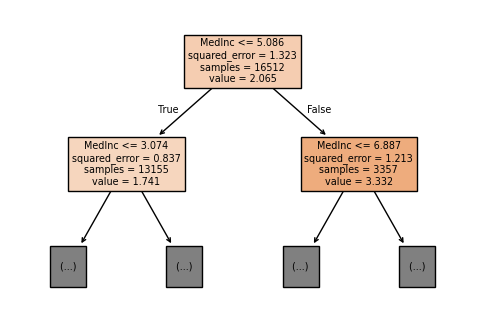

In [ ]:
# модель дерева решения для исходных данных
plt.figure(figsize=(6, 4))
plot_tree(tree_1, max_depth=1, filled=True, feature_names=X_train.columns);

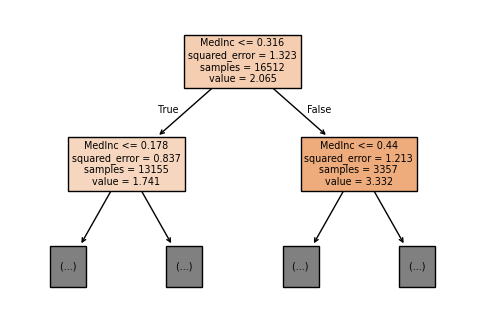

In [ ]:
# модель дерева решения для масштабированных данных
plt.figure(figsize=(6, 4))
plot_tree(tree_2, max_depth=1, filled=True, feature_names=X_train.columns);

## Summary

Вот мы и разобрались, зачем нужно масштабирование данных и как его применять.

- Масштабирование данных нужно для более **стабильного** обучения модели.
- Есть два основных вида масштабирование
    1. ***Нормализация***
        - После min = 0, max = 1 у всех признаков
        - Подход лучше зарекомендовал себя в подходах МЛ, которые работают с расстояниями (KNN)
    2. ***Стандартизация***
        - После mean = 0, std = 1 у всех признаков
        - Подход лучше зарекомендовал себя в линейных подходах МЛ (LinearRegression, SVM)
- Для моделей, основанных не **дереве решений** (DecisionTree, Bagging, RandomForest, Boosting) масштабирование данных **необязательно**